# 🚀 Session 8 – Advanced ML: Grid Search, Pipelines & Regularization

⏱ Estimated Time: 90 minutes

---

## 🎯 Where we are

Across Sessions 5–7 you built many models — trees, SVM, k-NN, logistic regression, Naive Bayes, and linear/polynomial regression. You also met two power tools in passing: **`Pipeline`** and **`GridSearchCV`**.

This session brings them together and adds the missing piece — **regularization** — to answer a recurring question: *how do we stop a model from overfitting, and how do we pick the best version of it automatically?*

We focus on four ideas:

1. **`GridSearchCV` for any estimator** — systematically tune hyperparameters (polynomial **degree** for regression, tree **depth** for classification) using cross-validation.
2. **Ridge and Lasso regression** — add a **penalty** that shrinks coefficients, taming overfitting and (for Lasso) performing automatic **feature selection**.
3. **Complex pipelines** — chain scaling, feature transforms, and different models into one clean, leakage-free object.
4. **Choosing a model** — compare several classifiers in pipelines and select the best by cross-validated score.

> 🆕 Ridge, Lasso, and systematic grid search were **not** covered in Orange (AI Wizards) — this is new, advanced ground.

---

**Session Objective**
- Master **hyperparameter tuning** with `GridSearchCV` and **k-fold cross-validation** for model selection.
- Implement **Ridge** and **Lasso** regression and compare them with ordinary least squares (OLS).
- Build **complex pipelines** combining scaling, feature transforms, and models.
- Interpret how **regularization affects coefficients and performance**, and review pitfalls like **data leakage** and **selection bias**.

**Datasets:** the **Dar es Salaam used-car** dataset for regression/regularization, and the **FinScope** financial-inclusion dataset for the multi-model classification comparison.

## 🧯 Why Regularization? (15 minutes)

In Session 7 you saw that a **high-degree polynomial** fits the training data ever more tightly but **generalizes worse** — its coefficients grow huge and wild, chasing noise. **Regularization** fixes this directly: it adds a **penalty for large coefficients** to the thing the model minimizes.

| Method | What it minimizes | Effect on coefficients |
|--------|-------------------|------------------------|
| **OLS (LinearRegression)** | Sum of squared errors only | No constraint — can grow huge |
| **Ridge (L2)** | Errors + α × Σ(coefficient²) | **Shrinks** all coefficients toward 0 (rarely exactly 0) |
| **Lasso (L1)** | Errors + α × Σ\|coefficient\| | Shrinks, and forces some to **exactly 0** → feature selection |

The strength is controlled by **α (alpha)**:
- **α = 0** → no penalty → same as OLS.
- **Small α** → light touch.
- **Large α** → heavy shrinkage → simpler, flatter model (risk of *underfitting* if too large).

<details>
<summary>Ridge vs Lasso — when to use which?</summary>

- **Ridge (L2)** keeps **all** features but shrinks them. Great when many features each contribute a little, or when features are **correlated**.
- **Lasso (L1)** can zero out features entirely, giving a **sparse, interpretable** model. Great when you suspect **only some** features matter and want automatic selection.
- Both need **scaled features** (the penalty is unfair otherwise) — so we always put them in a `Pipeline` with `StandardScaler`.
</details>

## 🚗 Setup: the used-car dataset (10 minutes)

Regularization matters most when there are **many features** — so we use the car dataset and expand it with polynomial features later. First, the standard setup.

In [1]:
## Import libraries
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures, StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, KFold, StratifiedKFold
from sklearn.metrics import mean_squared_error, r2_score, f1_score, accuracy_score

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
## Load the car dataset
data = pd.read_csv('car_prices.csv')

# Column groups
num_features = ['age_years', 'mileage_k_km', 'engine_size', 'horsepower']
cat_features = ['fuel', 'transmission', 'brand']
target = 'price_million_tzs'

X = data.drop(columns=[target])
y = data[target]

# Split FIRST (lock away the test set -> prevents data leakage)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", X_train.shape[0], " Test:", X_test.shape[0])

Train: 560  Test: 140

We build a helper that makes a **degree-3 polynomial pipeline** with any model plugged in. Degree 3 deliberately creates **many** features, so regularization has something to do.

<details>
<summary>⚠️ Reminder: pipelines prevent data leakage</summary>

Every transform (impute, polynomial, scale) is fit **inside** the pipeline, so during cross-validation it is refit on each training fold only — the test fold is never used to compute medians, scales, or powers. Doing these steps manually on the whole dataset would leak information and inflate your scores. This is the **cross-validation best practice** at the heart of this session.
</details>

In [3]:
# Helper: a degree-3 polynomial pipeline with a pluggable model
categorical_pipeline = Pipeline([('onehot', OneHotEncoder(drop='first', handle_unknown='ignore'))])

def make_pipeline(model, degree=3):
    numeric_pipeline = Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('poly', PolynomialFeatures(degree=degree, include_bias=False)),
        ('scale', StandardScaler())
    ])
    pre = ColumnTransformer([
        ('num', numeric_pipeline, num_features),
        ('cat', categorical_pipeline, cat_features)
    ])
    return Pipeline([('pre', pre), ('model', model)])

# How many features does degree-3 create?
prep = make_pipeline(LinearRegression()).fit(X_train, y_train)
n_features = prep.named_steps['pre'].transform(X_train).shape[1]
print("Features after degree-3 expansion + one-hot encoding:", n_features)

Features after degree-3 expansion + one-hot encoding: 41

## ⚖️ **OLS vs Ridge vs Lasso** (20 minutes)

With **41 features**, plain OLS has plenty of room to overfit. Let's compare it against Ridge and Lasso on the same pipeline.

In [4]:
# Compare the three models on identical degree-3 features
for name, model in [
    ('OLS (LinearRegression)', LinearRegression()),
    ('Ridge (alpha=1)', Ridge(alpha=1.0)),
    ('Lasso (alpha=0.1)', Lasso(alpha=0.1, max_iter=10000))
]:
    pipe = make_pipeline(model).fit(X_train, y_train)
    pred = pipe.predict(X_test)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    print(f"{name:26s} RMSE: {rmse:.2f}  R2: {r2_score(y_test, pred):.3f}")

OLS (LinearRegression)     RMSE: 6.36  R2: 0.945
Ridge (alpha=1)            RMSE: 6.28  R2: 0.946
Lasso (alpha=0.1)          RMSE: 6.48  R2: 0.943

On the **test** set all three are close — but the real difference shows up in **overfitting**. Compare each model's **training** R² against its **test** R²: a big gap means overfitting.

In [5]:
# Overfitting check: training vs test R2
ols   = make_pipeline(LinearRegression()).fit(X_train, y_train)
ridge = make_pipeline(Ridge(alpha=10)).fit(X_train, y_train)

print(f"OLS   -> Train R2: {ols.score(X_train, y_train):.3f}   Test R2: {ols.score(X_test, y_test):.3f}")
print(f"Ridge -> Train R2: {ridge.score(X_train, y_train):.3f}   Test R2: {ridge.score(X_test, y_test):.3f}")

OLS   -> Train R2: 0.957   Test R2: 0.945
Ridge -> Train R2: 0.928   Test R2: 0.930

🔎 **Interpretation**
- **OLS** has the larger train–test gap (0.957 vs 0.945) — it fits the training data harder, partly by chasing noise.
- **Ridge** *deliberately* fits the training data a bit less (0.928) but its test score is essentially as good (0.930), and the train–test gap is **tiny**. That stability is the whole point of regularization: trade a sliver of training fit for **robustness on unseen data**.

### 🔎 How regularization changes the coefficients

This is the most important thing to *see*. Using **degree-1** features (so the coefficients are directly interpretable), here is the same model fit three ways.

In [6]:
# Compare coefficients at degree 1 (interpretable)
def make_pipeline_d1(model):
    numeric_pipeline = Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())])
    pre = ColumnTransformer([('num', numeric_pipeline, num_features),
                             ('cat', categorical_pipeline, cat_features)])
    return Pipeline([('pre', pre), ('model', model)])

prep = make_pipeline_d1(LinearRegression()).fit(X_train, y_train)
feat_names = [f.replace('num__', '').replace('cat__', '')
              for f in prep.named_steps['pre'].get_feature_names_out()]

coef_compare = pd.DataFrame({
    'feature': feat_names,
    'OLS': make_pipeline_d1(LinearRegression()).fit(X_train, y_train).named_steps['model'].coef_,
    'Ridge_a10': make_pipeline_d1(Ridge(alpha=10)).fit(X_train, y_train).named_steps['model'].coef_,
    'Lasso_a0.5': make_pipeline_d1(Lasso(alpha=0.5, max_iter=20000)).fit(X_train, y_train).named_steps['model'].coef_,
})
coef_compare.round(2)

,feature,OLS,Ridge_a10,Lasso_a0.5
0,age_years,-21.60,-19.64,-22.08
1,mileage_k_km,-2.21,-3.90,-1.08
2,engine_size,-0.26,-0.18,0.00
3,horsepower,3.24,3.11,2.50
4,fuel_hybrid,8.86,6.44,1.84
5,fuel_petrol,-3.84,-3.99,-3.21
6,transmission_manual,-7.92,-7.63,-6.18
7,brand_Mercedes,7.55,14.29,13.34
8,brand_Nissan,-31.94,-20.40,-17.89
9,brand_Suzuki,-36.60,-24.55,-22.09


🔎 **Interpretation**
- **Ridge** pulls coefficients **toward zero** but keeps them all (e.g. Suzuki −36.6 → −24.6). Nothing is eliminated.
- **Lasso** sets `engine_size` to **exactly 0.00** — it decided that feature is redundant (horsepower already captures engine power) and **dropped it**. That is automatic **feature selection**.
- Both keep the big, genuinely-important effects (age, brand) while taming the rest.

### 📉 Watching coefficients shrink as α grows

The clearest picture: plot every coefficient as we increase α. Each line is one feature.

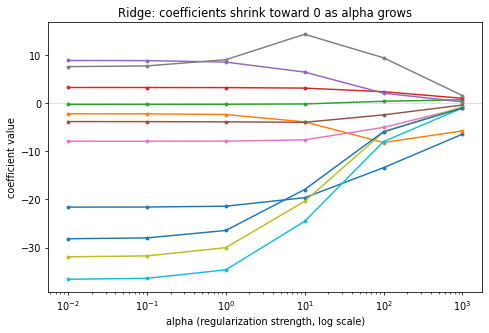

In [7]:
# Ridge coefficient paths
alphas = [0.01, 0.1, 1, 10, 100, 1000]
ridge_paths = np.array([
    make_pipeline_d1(Ridge(alpha=a)).fit(X_train, y_train).named_steps['model'].coef_
    for a in alphas
])
for i in range(ridge_paths.shape[1]):
    plt.plot(alphas, ridge_paths[:, i], marker='o', ms=3)
plt.xscale('log'); plt.axhline(0, color='gray', lw=0.6, ls=':')
plt.xlabel('alpha (regularization strength, log scale)')
plt.ylabel('coefficient value')
plt.title('Ridge: coefficients shrink toward 0 as alpha grows')
plt.show()

As α rises, **Ridge** smoothly squeezes every coefficient toward zero — but they approach zero **asymptotically**, never quite reaching it. Now watch **Lasso**.

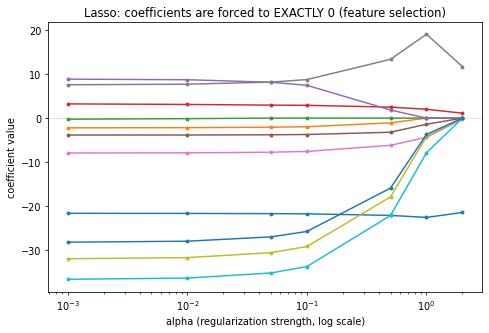

In [8]:
# Lasso coefficient paths
lasso_alphas = [0.001, 0.01, 0.05, 0.1, 0.5, 1, 2]
lasso_paths = np.array([
    make_pipeline_d1(Lasso(alpha=a, max_iter=20000)).fit(X_train, y_train).named_steps['model'].coef_
    for a in lasso_alphas
])
for i in range(lasso_paths.shape[1]):
    plt.plot(lasso_alphas, lasso_paths[:, i], marker='o', ms=3)
plt.xscale('log'); plt.axhline(0, color='gray', lw=0.6, ls=':')
plt.xlabel('alpha (regularization strength, log scale)')
plt.ylabel('coefficient value')
plt.title('Lasso: coefficients are forced to EXACTLY 0 (feature selection)')
plt.show()

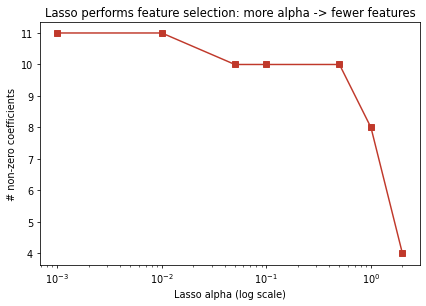

In [9]:
# How many features survive at each Lasso alpha?
nonzero = [int(np.sum(np.abs(p) > 1e-8)) for p in lasso_paths]
plt.plot(lasso_alphas, nonzero, marker='s', color='#c0392b')
plt.xscale('log')
plt.xlabel('Lasso alpha (log scale)')
plt.ylabel('# non-zero coefficients')
plt.title('Lasso feature selection: larger alpha -> fewer features')
plt.show()

🔎 **The key contrast**: Lasso lines hit **exactly zero** and stay there — as α grows, more and more features are switched off entirely. By α=2 only a handful of features remain. This is why Lasso doubles as a **feature-selection** tool, while Ridge only shrinks.

## 🔍 **Tuning α with `GridSearchCV`** (15 minutes)

We never guess α — we let cross-validation choose it. The parameter lives on the `model` step, so the grid key is `model__alpha`.

In [10]:
# GridSearch the best Ridge alpha (degree-3 pipeline)
kf = KFold(n_splits=5, shuffle=True, random_state=42)

ridge_grid = GridSearchCV(
    make_pipeline(Ridge(max_iter=10000)),
    param_grid={'model__alpha': [0.001, 0.01, 0.1, 1, 10, 100, 1000]},
    cv=kf, scoring='r2', n_jobs=-1
)
ridge_grid.fit(X_train, y_train)
print("Best Ridge alpha:", ridge_grid.best_params_)
print(f"Best CV R2: {ridge_grid.best_score_:.3f}")
print(f"Test R2:    {r2_score(y_test, ridge_grid.best_estimator_.predict(X_test)):.3f}")

Best Ridge alpha: {'model__alpha': 0.1}
Best CV R2: 0.950
Test R2:    0.946

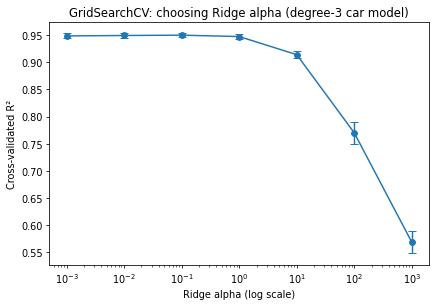

In [11]:
# Visualize CV R2 across alpha
res = pd.DataFrame(ridge_grid.cv_results_)
plt.errorbar([float(a) for a in res['param_model__alpha']], res['mean_test_score'],
             yerr=res['std_test_score'], marker='o', capsize=4)
plt.xscale('log')
plt.xlabel('Ridge alpha (log scale)'); plt.ylabel('Cross-validated R²')
plt.title('GridSearchCV: choosing Ridge alpha (degree-3 car model)')
plt.show()

The curve peaks at a **small α (0.1)** and falls off when α gets too large (over-shrinking → underfitting). Now the same for **Lasso**, where we also report how many features it kept.

In [12]:
# GridSearch the best Lasso alpha, and inspect feature selection
lasso_grid = GridSearchCV(
    make_pipeline(Lasso(max_iter=20000)),
    param_grid={'model__alpha': [0.001, 0.01, 0.1, 1, 10]},
    cv=kf, scoring='r2', n_jobs=-1
)
lasso_grid.fit(X_train, y_train)
print("Best Lasso alpha:", lasso_grid.best_params_)
print(f"Best CV R2: {lasso_grid.best_score_:.3f}")
print(f"Test R2:    {r2_score(y_test, lasso_grid.best_estimator_.predict(X_test)):.3f}")

best_lasso = lasso_grid.best_estimator_.named_steps['model']
n_zero = int(np.sum(np.abs(best_lasso.coef_) < 1e-8))
print(f"Lasso zeroed {n_zero} of {len(best_lasso.coef_)} coefficients (automatic feature selection)")

Best Lasso alpha: {'model__alpha': 0.01}
Best CV R2: 0.952
Test R2:    0.947
Lasso zeroed 19 of 41 coefficients (automatic feature selection)

🔎 **Interpretation**: tuned Lasso matches the best test R² (0.947) while using **fewer than half** the features — it threw away 19 of 41. A simpler model that performs just as well is usually the better choice (it is easier to interpret and less likely to overfit).

### 🧩 Tuning two things at once: degree **and** α

`GridSearchCV` shines when several knobs interact. Here we search the polynomial **degree** and Ridge **α** together — the grid is the **cross-product** of both lists.

In [13]:
# Joint grid: polynomial degree AND Ridge alpha
joint_grid = GridSearchCV(
    make_pipeline(Ridge(max_iter=10000)),
    param_grid={
        'pre__num__poly__degree': [1, 2, 3],
        'model__alpha': [0.1, 1, 10, 100]
    },
    cv=kf, scoring='r2', n_jobs=-1
)
joint_grid.fit(X_train, y_train)
print("Best combination:", joint_grid.best_params_)
print(f"Best CV R2: {joint_grid.best_score_:.3f}")
print(f"Test R2:    {r2_score(y_test, joint_grid.best_estimator_.predict(X_test)):.3f}")

Best combination: {'model__alpha': 0.1, 'pre__num__poly__degree': 3}
Best CV R2: 0.950
Test R2:    0.946

The search tried **3 degrees × 4 alphas = 12 combinations** (each with 5-fold CV) and picked degree 3 with light regularization (α=0.1). This is exactly the kind of systematic tuning the session is about — no manual trial-and-error.

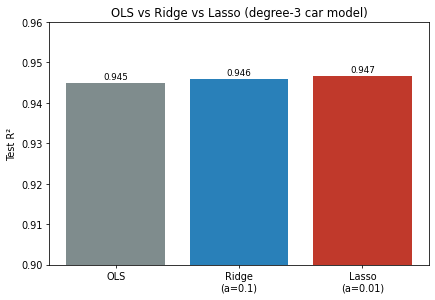

In [14]:
# Final visual comparison: OLS vs tuned Ridge vs tuned Lasso (degree-3)
bars = {}
for name, m in [('OLS', LinearRegression()),
                ('Ridge\n(a=0.1)', Ridge(alpha=0.1)),
                ('Lasso\n(a=0.01)', Lasso(alpha=0.01, max_iter=20000))]:
    p = make_pipeline(m).fit(X_train, y_train)
    bars[name] = r2_score(y_test, p.predict(X_test))
plt.bar(bars.keys(), bars.values(), color=['#7f8c8d', '#2980b9', '#c0392b'])
plt.ylim(0.9, 0.96); plt.ylabel('Test R²')
plt.title('OLS vs Ridge vs Lasso (degree-3 car model)')
for i, (k, v) in enumerate(bars.items()):
    plt.text(i, v + 0.001, f'{v:.3f}', ha='center')
plt.show()

**Practice Task:**
1. Replace Ridge with **`ElasticNet`** (`from sklearn.linear_model import ElasticNet`), which blends L1 and L2. Tune both `model__alpha` and `model__l1_ratio` with `GridSearchCV`.
2. How does its best CV R² compare to Ridge and Lasso?
3. How many coefficients does the tuned ElasticNet zero out — more like Ridge or like Lasso?

In [ ]:
# Your code here


## 🌳 **GridSearch for classification: tuning tree depth** (15 minutes)

Grid search is not just for regression. Switching to the **FinScope** classification problem (predicting bank-account ownership), we tune a **decision tree's depth** — the classic classification hyperparameter mentioned in the session brief.

In [15]:
# Load and prepare FinScope (binary, imbalanced)
fin = pd.read_csv('FinScope_cleaned1.csv')
fin['y'] = fin['has_bank_account'].map(
    {'no account': 0, 'two or three accounts': 1, 'more than three accounts': 1})
fin.drop('has_bank_account', axis=1, inplace=True)
fin = pd.get_dummies(fin, drop_first=True, dtype=int)

Xc = fin.drop('y', axis=1)
yc = fin['y']
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    Xc, yc, test_size=0.2, stratify=yc, random_state=42)
print("Positive rate (has account): {:.1%}".format(yc.mean()))

Positive rate (has account): 2.6%

In [16]:
# GridSearch a decision tree's depth and leaf size (optimize F1 on the rare class)
from sklearn.tree import DecisionTreeClassifier
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

tree_grid = GridSearchCV(
    Pipeline([('model', DecisionTreeClassifier(class_weight='balanced', random_state=42))]),
    param_grid={
        'model__max_depth': [2, 3, 5, 8, None],
        'model__min_samples_leaf': [1, 5, 20]
    },
    cv=skf, scoring='f1', n_jobs=-1
)
tree_grid.fit(Xc_train, yc_train)
print("Best tree params:", tree_grid.best_params_)
print(f"Best CV F1: {tree_grid.best_score_:.3f}")
print(f"Test F1:    {f1_score(yc_test, tree_grid.best_estimator_.predict(Xc_test)):.3f}")

Best tree params: {'model__max_depth': 5, 'model__min_samples_leaf': 1}
Best CV F1: 0.085

🔎 The search found a **moderate depth of 5** is best — deep enough to capture structure, shallow enough to avoid overfitting the imbalanced data. This is the classification analogue of choosing a polynomial degree.

## 🏆 **Choosing a model with pipelines** (15 minutes)

A common real workflow: wrap **several candidate models** in pipelines, cross-validate them all on the same footing, and **pick the winner**. Here we compare five classifiers on FinScope by cross-validated F1.

In [17]:
# Compare five classifiers, each in its own pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

candidates = {
    'Logistic':     Pipeline([('sc', StandardScaler()), ('m', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))]),
    'SVM-RBF':      Pipeline([('sc', StandardScaler()), ('m', SVC(kernel='rbf', class_weight='balanced', random_state=42))]),
    'k-NN':         Pipeline([('sc', StandardScaler()), ('m', KNeighborsClassifier())]),
    'NaiveBayes':   Pipeline([('sc', StandardScaler()), ('m', GaussianNB())]),
    'DecisionTree': Pipeline([('m', DecisionTreeClassifier(class_weight='balanced', random_state=42))]),
}

scores = {}
for name, pipe in candidates.items():
    cv = cross_val_score(pipe, Xc, yc, cv=skf, scoring='f1')
    scores[name] = cv.mean()
    print(f"{name:14s} CV F1: {cv.mean():.3f} +/- {cv.std():.3f}")

best_name = max(scores, key=scores.get)
print(f"\n--> Best model by CV F1: {best_name} ({scores[best_name]:.3f})")

Logistic       CV F1: 0.100 +/- 0.012
SVM-RBF        CV F1: 0.081 +/- 0.012
k-NN           CV F1: 0.000 +/- 0.000
NaiveBayes     CV F1: 0.082 +/- 0.075
DecisionTree   CV F1: 0.060 +/- 0.032

--> Best model by CV F1: Logistic (0.100)

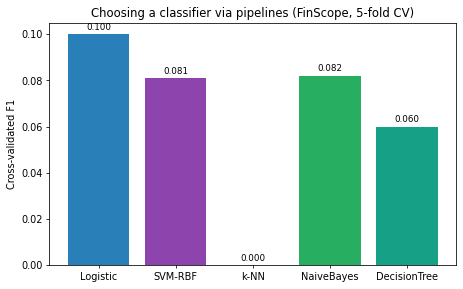

In [18]:
# Visualize the model comparison
plt.bar(scores.keys(), scores.values(),
        color=['#2980b9', '#8e44ad', '#e67e22', '#27ae60', '#16a085'])
plt.ylabel('Cross-validated F1')
plt.title('Choosing a classifier via pipelines (FinScope, 5-fold CV)')
for i, (k, v) in enumerate(scores.items()):
    plt.text(i, v + 0.002, f'{v:.3f}', ha='center')
plt.show()

🔎 **Interpretation**: on this imbalanced data, **Logistic Regression with balanced class weights** wins on F1 — it best identifies the rare account-holders. (All scores are modest because the problem is genuinely hard, as we saw in Session 6.) The point here is the **workflow**: pipelines let you swap models in and out and compare them fairly with a couple of lines.

## ⚠️ **Common Pitfalls: Data Leakage & Selection Bias** (5 minutes)

Two traps that quietly inflate your scores and lead to models that fail in production:

**1. Data leakage** — letting information from the test set into training.
- *Example:* fitting `StandardScaler` or `SimpleImputer` on the **whole dataset before splitting**, so the test rows influence the means/medians.
- *Fix:* always **split first**, and put every transform **inside a `Pipeline`** so it is refit on each training fold during cross-validation. This is the single most important habit from this session.

**2. Selection bias / "tuning on the test set"** — repeatedly checking the test set while choosing models or hyperparameters, then reporting that same test score.
- *Example:* trying 20 models, picking the one with the best **test** score, and quoting it. That number is optimistic — you have indirectly fit the test set.
- *Fix:* choose models and hyperparameters using **cross-validation on the training data only**. Touch the test set **once**, at the very end, for a single honest estimate.

> Golden rule: the **test set is sacred**. Use cross-validation for every decision; reveal the test set only for the final report.

##### 🧠 Key takeaways
- **Regularization** (Ridge L2, Lasso L1) curbs overfitting by penalizing large coefficients; **α** controls the strength.
- **Ridge** shrinks all coefficients; **Lasso** zeros some out → **feature selection**.
- **`GridSearchCV`** tunes any hyperparameter (regression **degree/α**, classification **tree depth**) via cross-validation, including several at once.
- **Pipelines** make complex preprocessing clean and **leakage-free**, and let you compare and select models easily.
- Guard against **data leakage** and **selection bias**: keep the test set for the final evaluation only.

## 🛠️ Mini Project: Find the Best Regularized Model (20 minutes)

**Scenario:** Build the best-tuned car-price predictor you can, using `car_prices.csv`.

**Setup:**
* Load the data; define numeric and categorical columns; split 80/20 (split **before** any transform).
* Build a degree-flexible pipeline: impute → polynomial → scale (numeric) + one-hot (categorical) → model.

**Regularization comparison:**
* Fit OLS, Ridge, and Lasso on the same degree-3 features. Report test RMSE and R² for each.
* For each, compare **train vs test R²**. Which overfits most?

**Coefficients:**
* At degree 1, print a coefficient table for OLS, Ridge and Lasso side by side.
* How many coefficients does Lasso zero out? Which features does it keep?

**Tuning:**
* Use `GridSearchCV` to tune Ridge `model__alpha` and, separately, Lasso `model__alpha` (5-fold CV).
* Run a **joint** grid over `pre__num__poly__degree` and `model__alpha`. Report the best combination.

**Conclusion:**
* Which regularized model would you ship, and why? Consider accuracy, simplicity (number of features), and overfitting.

Write Markdown notes at each step, and remember: choose everything by cross-validation, evaluate on the test set only once.

## 🚀 Capstone Project: Tuning and Regularization End-to-End (25 minutes)

Apply the full advanced toolkit to a regression problem of your choice.

**Dataset:** Use `car_prices.csv` (regression) — *or* revisit `dar_housing.csv`. *(Optionally, also tackle the FinScope classification task and tune a classifier.)*

**Tasks:**
1. **Load & Prepare:** Load the data, report missing values, define column groups, and split 80/20 **before** preprocessing. Explain why this ordering avoids **data leakage**.
2. **Pipeline:** Build a pipeline with imputing, polynomial expansion, scaling, and one-hot encoding feeding a regression model.
3. **OLS Baseline:** Fit ordinary least squares at a chosen degree. Report test RMSE and R², and the train–test R² gap.
4. **Ridge & Lasso:** Fit both with a starting α. Compare RMSE, R², and the train–test gap against OLS.
5. **Coefficient Analysis:** At degree 1, present OLS vs Ridge vs Lasso coefficients. Discuss shrinkage and which features Lasso removes (feature selection / significance).
6. **Tune α:** Use `GridSearchCV` (5-fold CV) to find the best α for Ridge and for Lasso. Plot CV score vs α.
7. **Joint Tuning:** Run a grid over **polynomial degree and α** together. Report the best combination and CV score.
8. **Final Evaluation:** Evaluate your single best tuned model on the **test set once** (RMSE, R²); plot predicted vs actual.
9. **Pitfalls Write-Up:** In a short paragraph, explain **data leakage** and **selection bias**, give one concrete example of each from this workflow, and state how you avoided them.
10. **Conclusions:** Recommend a final model and justify the choice on accuracy, simplicity, and robustness.

**Deliverable:** A Jupyter notebook with all code, outputs, plots (coefficient paths, CV-vs-α, predicted-vs-actual), answers to every task, and a short written conclusion.

By completing this capstone, learners demonstrate mastery of `GridSearchCV`, k-fold cross-validation, Ridge/Lasso regularization, complex leakage-free pipelines, and disciplined model selection on a practical problem.